# Car Market Pricing Analysis

**Business question:** A dealership group is reviewing its range. It wants to know:

1. **What drives a car's retail price?**
2. **Where do dealers earn the most margin**, in percentage and in dollars?
3. **What natural segments exist in the market**, and how do they differ on price, performance, fuel economy and margin?

**Data:** 387 car models (2004 US market) with retail price, dealer cost, engine and size specifications.
Make and model names are not included, so the analysis focuses on specifications rather than brands.

**Tools:** Python (pandas, scikit-learn, statsmodels), SQL (SQLite), matplotlib.

**Notebook outline**
1. Setup and data loading
2. Data quality checks
3. Feature engineering
4. SQL analysis
5. What drives price? (regression)
6. Market segmentation (PCA and k-means clustering)
7. Key findings and recommendations

## 1. Setup and data loading

In [1]:
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path("..")
RAW = ROOT / "data" / "raw" / "cars_full.csv"
PROCESSED = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
SQL_FILE = ROOT / "sql" / "analysis_queries.sql"
PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(exist_ok=True)

# Chart style: one consistent, colour-blind-safe palette for every figure
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GREY, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

In [2]:
raw = pd.read_csv(RAW)
print(raw.shape)
raw.head()

(387, 11)


,Retail Price,Dealer Cost,Engine Size (l),Cyl,HP,City MPG,Hwy MPG,Weight,Wheel Base,Len,Width
0,43755,39014,3.50,6,225,18,24,3880,115,197,72
1,46100,41100,3.50,6,225,18,24,3893,115,197,72
2,36945,33337,3.50,6,265,17,23,4451,106,189,77
3,89765,79978,3.20,6,290,17,24,3153,100,174,71
4,23820,21761,2.00,4,200,24,31,2778,101,172,68


Column names contain spaces and units, which are awkward in code and SQL. I'll rename them to clean snake_case names and add an ID so each car can be referenced.

In [3]:
cars = raw.rename(columns={
    "Retail Price": "retail_price", "Dealer Cost": "dealer_cost",
    "Engine Size (l)": "engine_l", "Cyl": "cylinders", "HP": "hp",
    "City MPG": "city_mpg", "Hwy MPG": "hwy_mpg", "Weight": "weight_lb",
    "Wheel Base": "wheelbase_in", "Len": "length_in", "Width": "width_in",
})
cars.insert(0, "car_id", range(1, len(cars) + 1))
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 387 entries, 0 to 386
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car_id        387 non-null    int64  
 1   retail_price  387 non-null    int64  
 2   dealer_cost   387 non-null    int64  
 3   engine_l      387 non-null    float64
 4   cylinders     387 non-null    int64  
 5   hp            387 non-null    int64  
 6   city_mpg      387 non-null    int64  
 7   hwy_mpg       387 non-null    int64  
 8   weight_lb     387 non-null    int64  
 9   wheelbase_in  387 non-null    int64  
 10  length_in     387 non-null    int64  
 11  width_in      387 non-null    int64  
dtypes: float64(1), int64(11)
memory usage: 36.4 KB


## 2. Data quality checks

In [4]:
checks = {
    "Missing values": int(cars.isna().sum().sum()),
    "Duplicate rows": int(cars.drop(columns="car_id").duplicated().sum()),
    "Dealer cost above retail price": int((cars.dealer_cost > cars.retail_price).sum()),
    "City MPG above highway MPG": int((cars.city_mpg > cars.hwy_mpg).sum()),
    "Non-positive numeric values": int((cars.drop(columns="car_id") <= 0).sum().sum()),
}
pd.Series(checks, name="count").to_frame()

,count
Missing values,0
Duplicate rows,0
Dealer cost above retail price,0
City MPG above highway MPG,1
Non-positive numeric values,0


In [5]:
cars.drop(columns='car_id').describe().T

,count,mean,std,min,25%,50%,75%,max
retail_price,387.00,"33,231.18","19,724.63","10,280.00","20,997.00","28,495.00","39,552.50","192,465.00"
dealer_cost,387.00,"30,440.65","17,901.18","9,875.00","19,575.00","26,155.00","36,124.00","173,560.00"
engine_l,387.00,3.13,1.01,1.40,2.30,3.00,3.80,6.00
cylinders,387.00,5.76,1.49,3.00,4.00,6.00,6.00,12.00
hp,387.00,214.44,70.26,73.00,165.00,210.00,250.00,493.00
city_mpg,387.00,20.31,5.26,10.00,18.00,19.00,21.50,60.00
hwy_mpg,387.00,27.26,5.64,12.00,24.00,27.00,30.00,66.00
weight_lb,387.00,"3,532.46",706.00,"1,850.00","3,107.00","3,469.00","3,922.00","6,400.00"
wheelbase_in,387.00,107.21,7.09,89.00,103.00,107.00,112.00,130.00
length_in,387.00,184.96,13.24,143.00,177.00,186.00,193.00,221.00


**Data quality findings**

- No missing values, no duplicates, and dealer cost is always below retail price. The data is clean.
- A handful of genuine extremes stand out:
  - **Hybrids** with 50–66 highway MPG, one of which has higher city than highway MPG. That is normal for hybrids, which recover energy when braking in town.
  - A **6.0L heavy SUV/truck** at 10/12 MPG.
  - A **$192k supercar**, more than double the next-highest price.
- **Decision:** keep all of them. They are real vehicles, not data errors. Removing them would hide real parts of the market. Instead, I use a log scale for price in the regression so the supercar doesn't dominate the fit.

## 3. Feature engineering

In [6]:
cars["margin_usd"] = cars.retail_price - cars.dealer_cost
cars["margin_pct"] = 100 * cars.margin_usd / cars.retail_price
cars["hp_per_1000_usd"] = 1000 * cars.hp / cars.retail_price
cars["power_to_weight"] = cars.hp / cars.weight_lb * 1000   # hp per 1,000 lb
cars["price_band"] = pd.cut(
    cars.retail_price, [0, 20_000, 30_000, 45_000, np.inf],
    labels=["Under $20k", "$20k–30k", "$30k–45k", "$45k+"], right=False,
)
cars[["retail_price", "margin_usd", "margin_pct", "hp_per_1000_usd", "power_to_weight", "price_band"]].head()

,retail_price,margin_usd,margin_pct,hp_per_1000_usd,power_to_weight,price_band
0,43755,4741,10.84,5.14,57.99,$30k–45k
1,46100,5000,10.85,4.88,57.80,$45k+
2,36945,3608,9.77,7.17,59.54,$30k–45k
3,89765,9787,10.90,3.23,91.98,$45k+
4,23820,2059,8.64,8.40,71.99,$20k–30k


## 4. SQL analysis

I load the cleaned data into a SQLite database and run the queries saved in [`sql/analysis_queries.sql`](../sql/analysis_queries.sql).
SQLite ships with Python, so no database server is needed. The same `.db` file opens directly in DB Browser for SQLite.

In [7]:
db_path = PROCESSED / "cars.db"
with sqlite3.connect(db_path) as con:
    cars.drop(columns="price_band").to_sql("cars", con, if_exists="replace", index=False)

# Split the .sql file into named queries ("-- name: xxx" markers)
queries, current = {}, None
for line in SQL_FILE.read_text(encoding="utf-8").splitlines():
    if line.startswith("-- name:"):
        current = line.split(":", 1)[1].strip()
        queries[current] = []
    elif current:
        queries[current].append(line)
queries = {k: "\n".join(v).strip() for k, v in queries.items()}

def run(name):
    with sqlite3.connect(db_path) as con:
        return pd.read_sql_query(queries[name], con)

list(queries)

['market_overview',
 'data_quality_checks',
 'margin_by_price_band',
 'margin_by_cylinders',
 'best_value_performance',
 'fuel_economy_by_engine_size',
 'price_rank_within_cylinders']

In [8]:
run('market_overview')

,models,avg_price,min_price,max_price,avg_margin_usd,avg_margin_pct
0,387,"33,231.00",10280,192465,"2,791.00",8.02


In [9]:
run('data_quality_checks')

,car_id,retail_price,hp,city_mpg,hwy_mpg,flag
0,358,20510,110,59,51,City MPG above highway (typical of hybrids)
1,298,192465,477,17,24,Extreme price (supercar)
2,139,20140,93,46,51,Very high MPG (likely hybrid)
3,144,19110,73,60,66,Very high MPG (likely hybrid)
4,241,76870,292,13,14,Very low MPG (heavy truck/SUV)
5,149,49995,316,10,12,Very low MPG (heavy truck/SUV)


### 4.1 Where is dealer margin highest?

In [10]:
band = run("margin_by_price_band")
band

,price_band,models,avg_price,avg_margin_usd,avg_margin_pct
0,1. Under $20k,83,"15,848.00","1,046.00",6.43
1,2. $20k–30k,126,"24,770.00","2,010.00",8.08
2,3. $30k–45k,113,"36,429.00","3,104.00",8.50
3,4. $45k+,65,"66,271.00","5,987.00",9.12


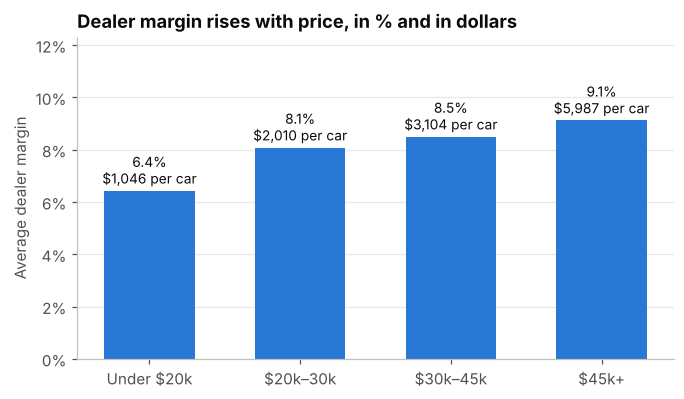

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = band.price_band.str[3:]
bars = ax.bar(labels, band.avg_margin_pct, color=BLUE, width=0.6)
for b, pct, usd in zip(bars, band.avg_margin_pct, band.avg_margin_usd):
    ax.text(b.get_x() + b.get_width() / 2, pct + 0.15, f"{pct:.1f}%\n${usd:,.0f} per car",
            ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, band.avg_margin_pct.max() * 1.35)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Average dealer margin")
ax.set_title("Dealer margin rises with price, in % and in dollars")
ax.grid(axis="x", visible=False)
fig.savefig(IMAGES / "margin_by_price_band.png")
plt.show()

Cars over $45k carry about **9.1% margin, roughly $6,000 per car**. Cars under $20k carry about **6.4%, roughly $1,000 per car**.
In dollar terms, one premium sale earns about as much margin as **six** budget sales.

In [12]:
run('margin_by_cylinders')

,cylinders,models,avg_price,avg_hp,avg_margin_pct
0,3,1,"19,110.00",73.00,6.27
1,4,123,"20,047.00",151.00,6.87
2,5,7,"37,187.00",228.00,5.77
3,6,179,"32,685.00",220.00,8.48
4,8,75,"53,460.00",299.00,9.09
5,12,2,"127,545.00",493.00,6.91


### 4.2 Fuel economy and value

In [13]:
run('fuel_economy_by_engine_size')

,engine_band,models,avg_hwy_mpg,avg_city_mpg,avg_price
0,1. Under 2.0L,47,35.00,28.40,"18,218.00"
1,2. 2.0–2.9L,116,29.30,22.20,"24,326.00"
2,3. 3.0–3.9L,138,26.20,18.70,"33,914.00"
3,4. 4.0–4.9L,66,22.60,16.30,"47,622.00"
4,5. 5.0L+,20,19.90,14.60,"67,960.00"


In [14]:
run('best_value_performance')

,car_id,retail_price,hp,hwy_mpg,hp_per_1000_usd
0,310,10995,140,35,12.73
1,330,12884,155,31,12.03
2,331,14500,155,31,10.69
3,269,26910,287,26,10.67
4,123,18345,193,29,10.52
5,272,23290,245,26,10.52
6,344,21965,225,29,10.24
7,190,10280,104,33,10.12
8,135,23760,240,30,10.10
9,352,10760,108,43,10.04


In [15]:
run('price_rank_within_cylinders')

,car_id,cylinders,retail_price,price_rank,diff_from_group_avg
0,144,3,19110,1,0.00
1,304,4,43175,1,"23,128.00"
2,307,4,40845,2,"20,798.00"
3,305,4,40670,3,"20,623.00"
4,376,5,42565,1,"5,378.00"
5,377,5,40565,2,"3,378.00"
6,382,5,37885,3,698.00
7,298,6,192465,1,"159,780.00"
8,4,6,89765,2,"57,080.00"
9,296,6,84165,3,"51,480.00"


## 5. What drives price?

First I check which specifications move together with price. Then I fit a regression to put a number on the effect of each one.

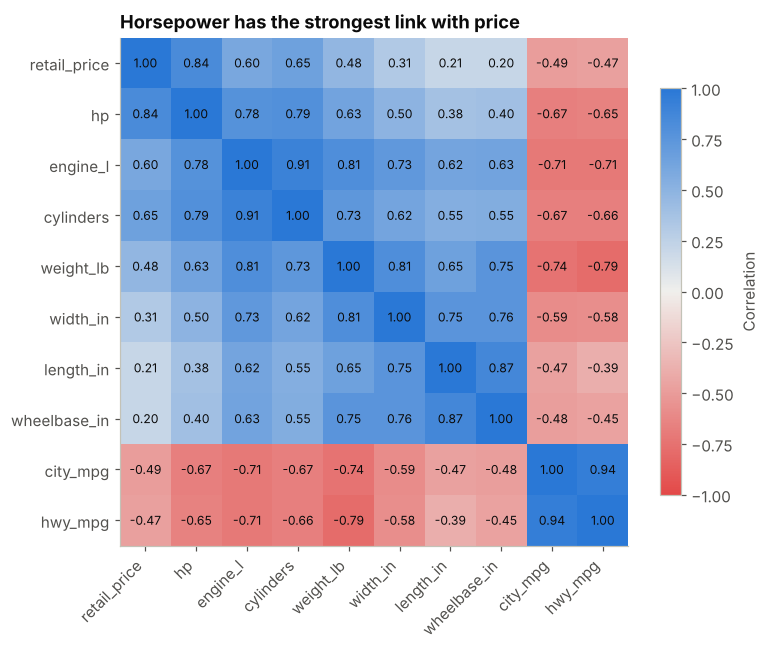

In [16]:
corr_cols = ["retail_price", "hp", "engine_l", "cylinders", "weight_lb",
             "width_in", "length_in", "wheelbase_in", "city_mpg", "hwy_mpg"]
corr = cars[corr_cols].corr()

from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#e34948", "#f0efec", "#2a78d6"])

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
ax.grid(False)
ax.set_title("Horsepower has the strongest link with price")
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlation")
fig.savefig(IMAGES / "correlation_heatmap.png")
plt.show()

Horsepower has the strongest correlation with price (**0.84**). Engine size, cylinders and weight are also strongly related to price, but they are also related to each other (a bigger engine means more cylinders and more horsepower).
Because of that overlap, a regression with all of them would give unstable, hard-to-explain coefficients. So I start with horsepower alone and then check how much the other features add.

I model **log(price)**. Each coefficient then reads as a percentage change in price, and the long tail of very expensive cars has less pull on the fit.

In [17]:
m_hp = smf.ols("np.log(retail_price) ~ hp", data=cars).fit()
m_full = smf.ols("np.log(retail_price) ~ hp + weight_lb + hwy_mpg + width_in + wheelbase_in", data=cars).fit()

pct_per_10hp = (np.exp(m_hp.params["hp"] * 10) - 1) * 100
print(f"Horsepower only:   R² = {m_hp.rsquared:.3f}")
print(f"Five features:     R² = {m_full.rsquared:.3f}")
print(f"Each extra 10 hp is associated with a {pct_per_10hp:.1f}% higher retail price")

Horsepower only:   R² = 0.770
Five features:     R² = 0.796
Each extra 10 hp is associated with a 6.3% higher retail price


In [18]:
m_full.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,9.9786,0.357,27.949,0.000,9.277,10.681
hp,0.0056,0.000,25.602,0.000,0.005,0.006
weight_lb,0.0003,4.15e-05,6.714,0.000,0.000,0.000
hwy_mpg,0.0102,0.004,2.819,0.005,0.003,0.017
width_in,-0.0192,0.006,-3.118,0.002,-0.031,-0.007
wheelbase_in,-0.0074,0.003,-2.677,0.008,-0.013,-0.002


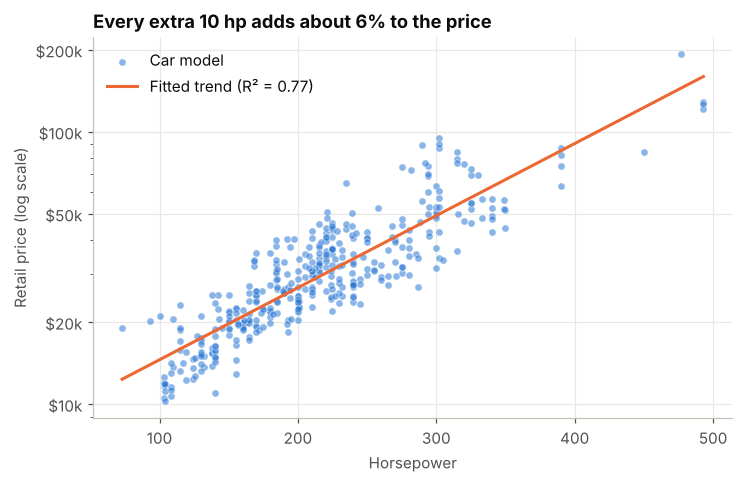

In [19]:
x = np.linspace(cars.hp.min(), cars.hp.max(), 200)
y = np.exp(m_hp.params["Intercept"] + m_hp.params["hp"] * x)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(cars.hp, cars.retail_price, s=22, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.5,
           label="Car model")
ax.plot(x, y, color=ORANGE, linewidth=2, label=f"Fitted trend (R² = {m_hp.rsquared:.2f})")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}k"))
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_yticks([10_000, 20_000, 50_000, 100_000, 200_000])
ax.set_xlabel("Horsepower")
ax.set_ylabel("Retail price (log scale)")
ax.set_title(f"Every extra 10 hp adds about {pct_per_10hp:.0f}% to the price")
ax.legend(frameon=False, loc="upper left")
fig.savefig(IMAGES / "price_vs_horsepower.png")
plt.show()

**Interpretation**

- **Horsepower alone explains about 77% of the variation in (log) price.** Adding weight, fuel economy and size only lifts this to about 80%.
- Each extra **10 hp** is associated with roughly **6% higher** retail price.
- Once horsepower is accounted for, extra weight still adds a little to price. Larger exterior dimensions slightly reduce it, which suggests big family cars and trucks are priced lower than their size alone would imply.
- **Caveat:** this shows association, not causation. Horsepower partly stands in for unmeasured factors like brand, luxury trim and technology, which this dataset doesn't include.

## 6. Market segmentation

Can the market be split into natural groups of similar cars? I use the **specifications only** (no price), so the segments describe *what the cars are*. Price and margin are then compared across segments afterwards.

Steps:
1. **Standardise** the features, because they are on very different scales (pounds vs. litres).
2. **PCA** to check how many underlying dimensions the data really has.
3. **K-means** to form segments, with the number of segments chosen from silhouette scores and interpretability.

In [20]:
spec_cols = ["engine_l", "cylinders", "hp", "city_mpg", "hwy_mpg",
             "weight_lb", "wheelbase_in", "length_in", "width_in"]
X = StandardScaler().fit_transform(cars[spec_cols])

pca = PCA().fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
print("Cumulative variance explained:", np.round(cum, 3))

loadings = pd.DataFrame(pca.components_[:2].T, index=spec_cols, columns=["PC1", "PC2"])
loadings

Cumulative variance explained: [0.7   0.834 0.902 0.933 0.957 0.978 0.988 0.996 1.   ]


,PC1,PC2
engine_l,0.37,-0.09
cylinders,0.35,-0.18
hp,0.31,-0.36
city_mpg,-0.33,0.31
hwy_mpg,-0.33,0.35
weight_lb,0.37,0.05
wheelbase_in,0.31,0.50
length_in,0.30,0.52
width_in,0.34,0.30


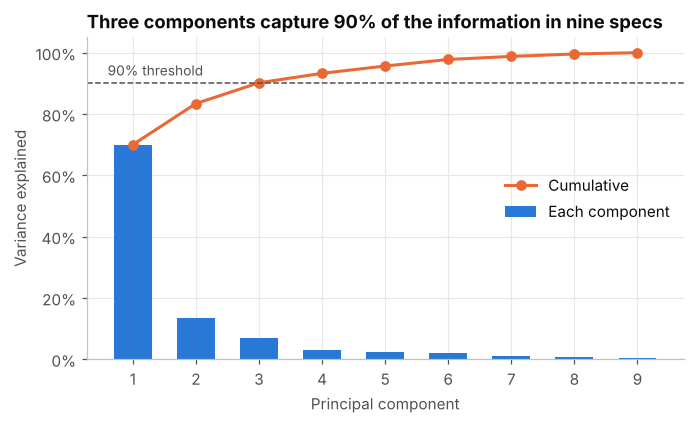

In [21]:
k = np.arange(1, len(cum) + 1)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(k, pca.explained_variance_ratio_ * 100, color=BLUE, width=0.6, label="Each component")
ax.plot(k, cum * 100, color=ORANGE, marker="o", markersize=6, linewidth=2, label="Cumulative")
ax.axhline(90, color=INK_2, linestyle="--", linewidth=1)
ax.text(0.6, 91.5, "90% threshold", va="bottom", color=INK_2, fontsize=9)
ax.set_xticks(k)
ax.set_xlabel("Principal component")
ax.set_ylabel("Variance explained")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Three components capture 90% of the information in nine specs")
ax.legend(frameon=False, loc="center right")
fig.savefig(IMAGES / "pca_variance.png")
plt.show()

- **PC1 (70% of variance) is overall "size and power".** Every spec loads on it, with fuel economy pointing the opposite way. Big, powerful cars use more fuel.
- **PC2 (13%) separates long, roomy, economical cars from powerful ones of a similar overall size.** Length, wheelbase and MPG sit on one side and horsepower on the other.
- Three components capture **90%** of the information in nine specifications. The market is much simpler than nine columns suggest.

### Choosing the number of segments

In [22]:
rows = []
for n in range(2, 8):
    km = KMeans(n_clusters=n, n_init=20, random_state=0).fit(X)
    rows.append({"segments": n, "silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_})
pd.DataFrame(rows)

,segments,silhouette,inertia
0,2,0.36,"1,931.23"
1,3,0.32,"1,418.94"
2,4,0.31,"1,251.13"
3,5,0.25,"1,086.68"
4,6,0.25,961.52
5,7,0.26,867.34


The silhouette score is highest for 2 segments and falls gradually through 4, then drops sharply at 5.
Two segments ("small" vs "big") is too coarse to be useful for a business. **Four segments** keep a reasonable silhouette (0.31) and give groups a sales team can clearly name and act on. So I choose **k = 4**: a balance between the statistics and business usefulness.

In [23]:
km = KMeans(n_clusters=4, n_init=20, random_state=0).fit(X)
cars["segment_id"] = km.labels_

profile = cars.groupby("segment_id").agg(
    models=("car_id", "size"), median_price=("retail_price", "median"),
    median_hp=("hp", "median"), median_hwy_mpg=("hwy_mpg", "median"),
    median_weight=("weight_lb", "median"), median_length=("length_in", "median"),
    avg_margin_pct=("margin_pct", "mean"), avg_margin_usd=("margin_usd", "mean"),
)

# Name each segment from its profile (ordered by median price)
def name_segment(r):
    if r.median_hwy_mpg >= 31:
        return "Economy compact"
    if r.median_hp >= 300:
        return "Performance & luxury"
    if r.median_weight >= 4_000:
        return "Large V8 / SUV & truck"
    return "Mainstream mid-size"

profile["segment"] = profile.apply(name_segment, axis=1)
assert profile.segment.is_unique, "Segment naming rules overlap; check the profiles"
cars["segment"] = cars.segment_id.map(profile.segment)
profile = profile.set_index("segment").sort_values("median_price")
profile

,models,median_price,median_hp,median_hwy_mpg,median_weight,median_length,avg_margin_pct,avg_margin_usd
segment,,,,,,,,
Economy compact,94,"16,596.00",138.00,33.00,"2,692.00",174.00,6.82,"1,286.22"
Mainstream mid-size,178,"28,744.50",210.00,27.00,"3,459.00",186.00,8.09,"2,587.48"
Large V8 / SUV & truck,71,"34,495.00",240.00,23.00,"4,376.00",201.00,8.97,"3,551.70"
Performance & luxury,44,"53,897.50",317.50,23.00,"3,950.50",187.00,8.81,"5,597.43"


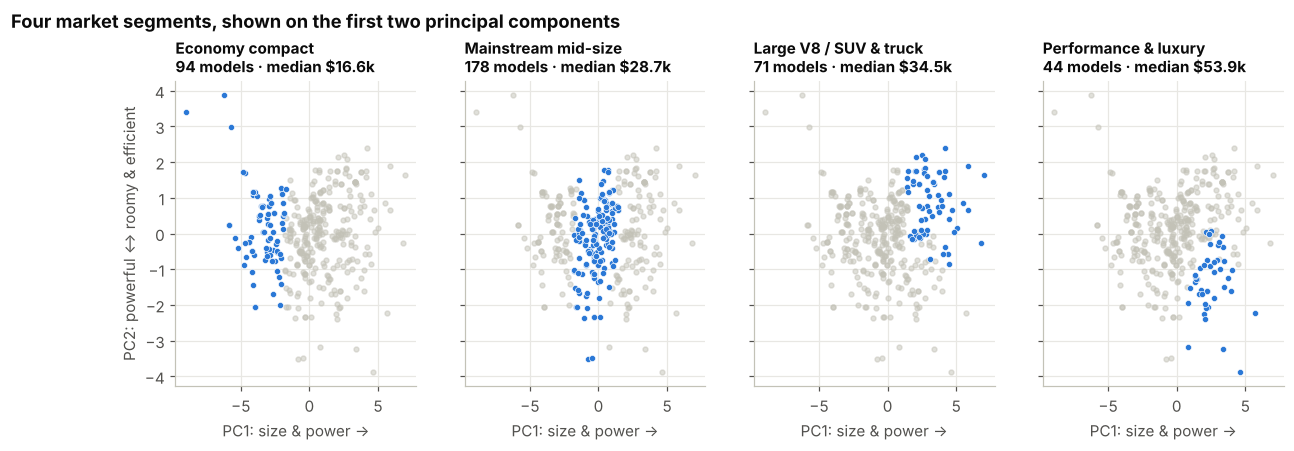

In [24]:
order = profile.index.tolist()
pcs = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharex=True, sharey=True)
for ax, seg in zip(axes, order):
    mask = (cars.segment == seg).values
    ax.scatter(pcs[~mask, 0], pcs[~mask, 1], s=10, color=GREY, alpha=0.5)
    ax.scatter(pcs[mask, 0], pcs[mask, 1], s=16, color=BLUE, edgecolor="white", linewidth=0.4)
    p = profile.loc[seg]
    ax.set_title(f"{seg}\n{int(p.models)} models · median ${p.median_price/1000:,.1f}k", fontsize=10)
    ax.set_xlabel("PC1: size & power →")
axes[0].set_ylabel("PC2: powerful ↔ roomy & efficient")
fig.suptitle("Four market segments, shown on the first two principal components",
             x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.06)
fig.savefig(IMAGES / "market_segments.png")
plt.show()

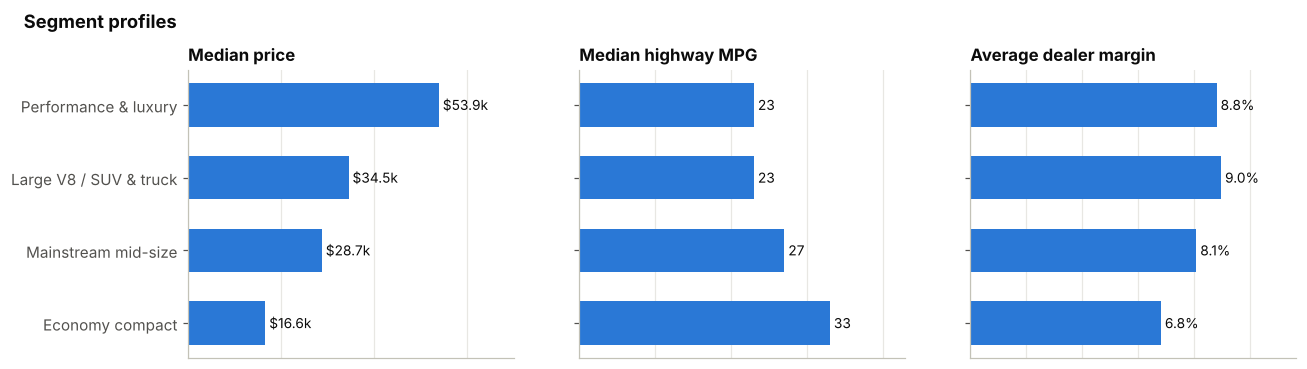

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
metrics = [("median_price", "Median price", lambda v: f"${v/1000:,.1f}k"),
           ("median_hwy_mpg", "Median highway MPG", lambda v: f"{v:.0f}"),
           ("avg_margin_pct", "Average dealer margin", lambda v: f"{v:.1f}%")]
for ax, (col, title, fmt) in zip(axes, metrics):
    vals = profile[col]
    ax.barh(order, vals, color=BLUE, height=0.6)
    for i, v in enumerate(vals):
        ax.text(v, i, " " + fmt(v), va="center", fontsize=9, color=INK)
    ax.set_xlim(0, vals.max() * 1.3)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelbottom=False, length=0)
fig.suptitle("Segment profiles", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.04)
fig.savefig(IMAGES / "segment_profiles.png")
plt.show()

**Segment insights**

| Segment | What it is | Commercial angle |
|---|---|---|
| **Economy compact** | Small 4-cylinder cars, best fuel economy | Lowest margin %. A volume and footfall business. |
| **Mainstream mid-size** | 6-cylinder family saloons, the biggest group | The core of the market, with average margin |
| **Large V8 / SUV & truck** | Heavy, long, 8-cylinder vehicles | **Highest margin %** at only a mid-range price |
| **Performance & luxury** | 300+ hp, premium priced | Biggest dollar margin per sale |

The most useful finding: **large V8 vehicles earn a margin percentage as high as performance and luxury cars, at around a third lower price.** That makes them a strong segment for a dealer to stock and promote.

## 7. Save outputs for Power BI

In [26]:
cars["price_band_order"] = cars.price_band.cat.codes + 1
cars["segment_order"] = cars.segment.map({s: i + 1 for i, s in enumerate(order)})
export_cols = ["car_id", "segment", "segment_order", "price_band", "price_band_order", "retail_price", "dealer_cost", "margin_usd", "margin_pct",
               "hp", "engine_l", "cylinders", "city_mpg", "hwy_mpg", "weight_lb",
               "length_in", "width_in", "wheelbase_in", "hp_per_1000_usd", "power_to_weight"]
cars[export_cols].to_csv(PROCESSED / "cars_powerbi.csv", index=False)
profile.round(2).to_csv(PROCESSED / "segment_summary.csv")
print("Saved:", PROCESSED / "cars_powerbi.csv", "and", PROCESSED / "segment_summary.csv")

Saved: ../data/processed/cars_powerbi.csv and ../data/processed/segment_summary.csv


## 8. Key findings and recommendations

**Findings**
1. **Horsepower is the main price driver.** On its own it explains about 77% of price variation, and each extra 10 hp is associated with roughly 6% higher price.
2. **Margin grows with price.** Margin rises from about 6.4% under $20k to about 9.1% above $45k. In dollars, one premium sale (about $6,000 margin) earns as much as roughly six budget sales (about $1,000 each).
3. **The market has four clear segments.** Three underlying dimensions capture 90% of the differences between cars.
4. **Large V8 / SUV & truck models are the margin sweet spot.** They earn about 9% margin at a median price of about $34k.

**Recommendations for the dealership group**
- **Prioritise stock and marketing for the Large V8 / SUV & truck segment.** It has premium-level margin percentages with mid-market prices and a broader buyer base.
- **Treat economy compacts as a volume and customer-acquisition play,** not a profit centre. Pair them with finance, servicing and trade-in offers to lift the value of each customer.
- **In pricing conversations, lead with horsepower and performance,** because that is what the market rewards most strongly.

**Limitations and next steps**
- The data covers one model year and has no make, model, trim or sales volumes. Adding sales volumes would show whether high-margin segments also sell well.
- The margin figures are list-price margins. Real-world discounts and manufacturer incentives would change them.